# BFMNs from association and valence task

In [1]:
import os
import sys
import pandas as pd

# Add project root (parent of this scripts/ folder) to sys.path once
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Now import from ../src folder
from src.models_and_vars import load_env_vars, ensure_nltk_path, init_spacy_and_emo
from src.valence import fmn_valence_stats, categorize_valence_multiple, plot_valence_distribution
from src.fmtools import (
    monitor_memory,
    draw_fmnts,
    make_emo_flowers,
    extract_bfmn_structural_features,
    all_fmns_features_df,
    verify_and_report_nodes,
    inspect_fmn
)
from src.io import export_df, export_whole_fmn_multiple_custom, import_fmnt_from_old_text_format
from src.data_processing import (
    subset_by_group_labels,
    build_association_df,
    filter_associations_by_occurrences,
)

pd.set_option('display.max_rows', 100)

In [2]:
# you do not need to run these download commands every time. nltk.download()
# saves these data packages to your local file system in the nltk_data directory.
# Once they are downloaded, they are available for NLTK to use in any session.

'''nltk.download('wordnet')
nltk.download('omw-1.4') # for italian and multilingual support, if needed
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng') # for word tokenization
nltk.download('averaged_perceptron_tagger') # for POS tagging
'''


"nltk.download('wordnet')\nnltk.download('omw-1.4') # for italian and multilingual support, if needed\nnltk.download('punkt')\nnltk.download('punkt_tab')\nnltk.download('averaged_perceptron_tagger_eng') # for word tokenization\nnltk.download('averaged_perceptron_tagger') # for POS tagging\n"

# Environment and models settings

In [3]:
# Set language once; everything else adapts
language = "italian"  # or "english"
env_file_path = "../env"

# Execute setup
load_env_vars(env_file_path, language=language)
ensure_nltk_path()

nlp, emo = init_spacy_and_emo(language)

# Also preload both models for explicit use
nlp_en, _ = init_spacy_and_emo("english")
nlp_it, _ = init_spacy_and_emo("italian")

Loaded SPACY_MODEL_PATH_EN: /home/franaz/coding/spacy-models/en_core_web_lg/en_core_web_lg-3.8.0
Loaded SPACY_MODEL_PATH_IT: /home/franaz/coding/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'it_core_news_lg' (3.7.0) was trained with spaCy v3.7.0 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


# fmn and paths settings

In [4]:
# Dynamic output paths system for pipelines
base_output_path = '../out'
project_name = 'merged'
formatted_data_dir = 'formatting'
use_prelemmatized_brysbaert = True # A lot faster (highly suggested, but needs pre-lemmatized data)
# Set the type of fmn to use: 'bfmns' or 'tfmns'
# (this is used for the folder name, not for the file names)
fmn_type = 'bfmns'
# Keywords that we want to check for in the textual data. If not empty,
# semantic frame plots will be created for these keywords. Otherwise,
# the full FMNs will be visualized.
keywords = []
keywords = ["mathematics","anxiety","stress","depression","statistics","computer science","physics","science","exam","grade","school","university","calculus","discipline","subject","scientist","research","well-being","teacher","professor"]
# Lemmatization setting
lemmatize = False

# Types of output: aggregated and individual (entire dataset vs per participant FMNs)
# Choose any subset: {'aggregated'}, {'individual'}, or both
# How to use:
# Only aggregated: methods = {'aggregated'}
# Only individual: methods = {'individual'}
# Both: methods = {'aggregated', 'individual'}
ALLOWED_METHODS = {'aggregated', 'individual'}
methods = {'aggregated'}
methods = {m.strip().lower() for m in (methods if isinstance(methods, (list, set, tuple)) else [methods])}
methods = methods & ALLOWED_METHODS
if not methods:
    raise ValueError("No valid methods selected. Use 'aggregated' and/or 'individual'.")

# Groups to subset the data (if needed). Use labels and .startswith() condition
# from the 'participant_id' column to create groups.
group_name = 'researchers_filtered'  # fmn name when using groups
if group_name:
    fmn_type = f'{group_name}_{fmn_type}'

# If dfs_and_group_labels is longer than 1, merge the data from the different paths.
dfs_and_group_labels = []
df1 = pd.read_csv('../out/formatting/splitted_dfs/high_anxiety_high_school_gpt_oss.csv')
dfs_and_group_labels = [
    (df1, None)   # list of (df, group_labels)
]

# print all unique participants
all_participants = set()
for df, group_labels in dfs_and_group_labels:
    all_participants.update(df['participant_id'].unique())
print(f"All unique participants across datasets: {len(all_participants)}")
print(f"Unique participants labels: {all_participants}\n")

# Resolve output directories
if methods == {'aggregated'}:
    files_output_dir = f'{base_output_path}/{project_name}/aggregated/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/aggregated/{formatted_data_dir}/{fmn_type}'
if methods == {'individual'}:
    files_output_dir = f'{base_output_path}/{project_name}/individual/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/individual/{formatted_data_dir}/{fmn_type}'

All unique participants across datasets: 28
Unique participants labels: {'gpt_oss_226', 'gpt_oss_960', 'gpt_oss_949', 'gpt_oss_847', 'gpt_oss_745', 'gpt_oss_882', 'gpt_oss_305', 'gpt_oss_253', 'gpt_oss_439', 'gpt_oss_972', 'gpt_oss_290', 'gpt_oss_748', 'gpt_oss_269', 'gpt_oss_128', 'gpt_oss_643', 'gpt_oss_721', 'gpt_oss_223', 'gpt_oss_107', 'gpt_oss_095', 'gpt_oss_706', 'gpt_oss_540', 'gpt_oss_547', 'gpt_oss_579', 'gpt_oss_131', 'gpt_oss_196', 'gpt_oss_195', 'gpt_oss_508', 'gpt_oss_126'}



## Run the pipeline

### Aggregated pipeline

Starting pipeline...

Current memory usage: 4409.88 MB
[✔] Network exported to '../out/merged/aggregated/researchers_filtered_bfmns/researchers_filtered.txt'
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 4405.94 MB
Drawing TFMN: researchers_filtered


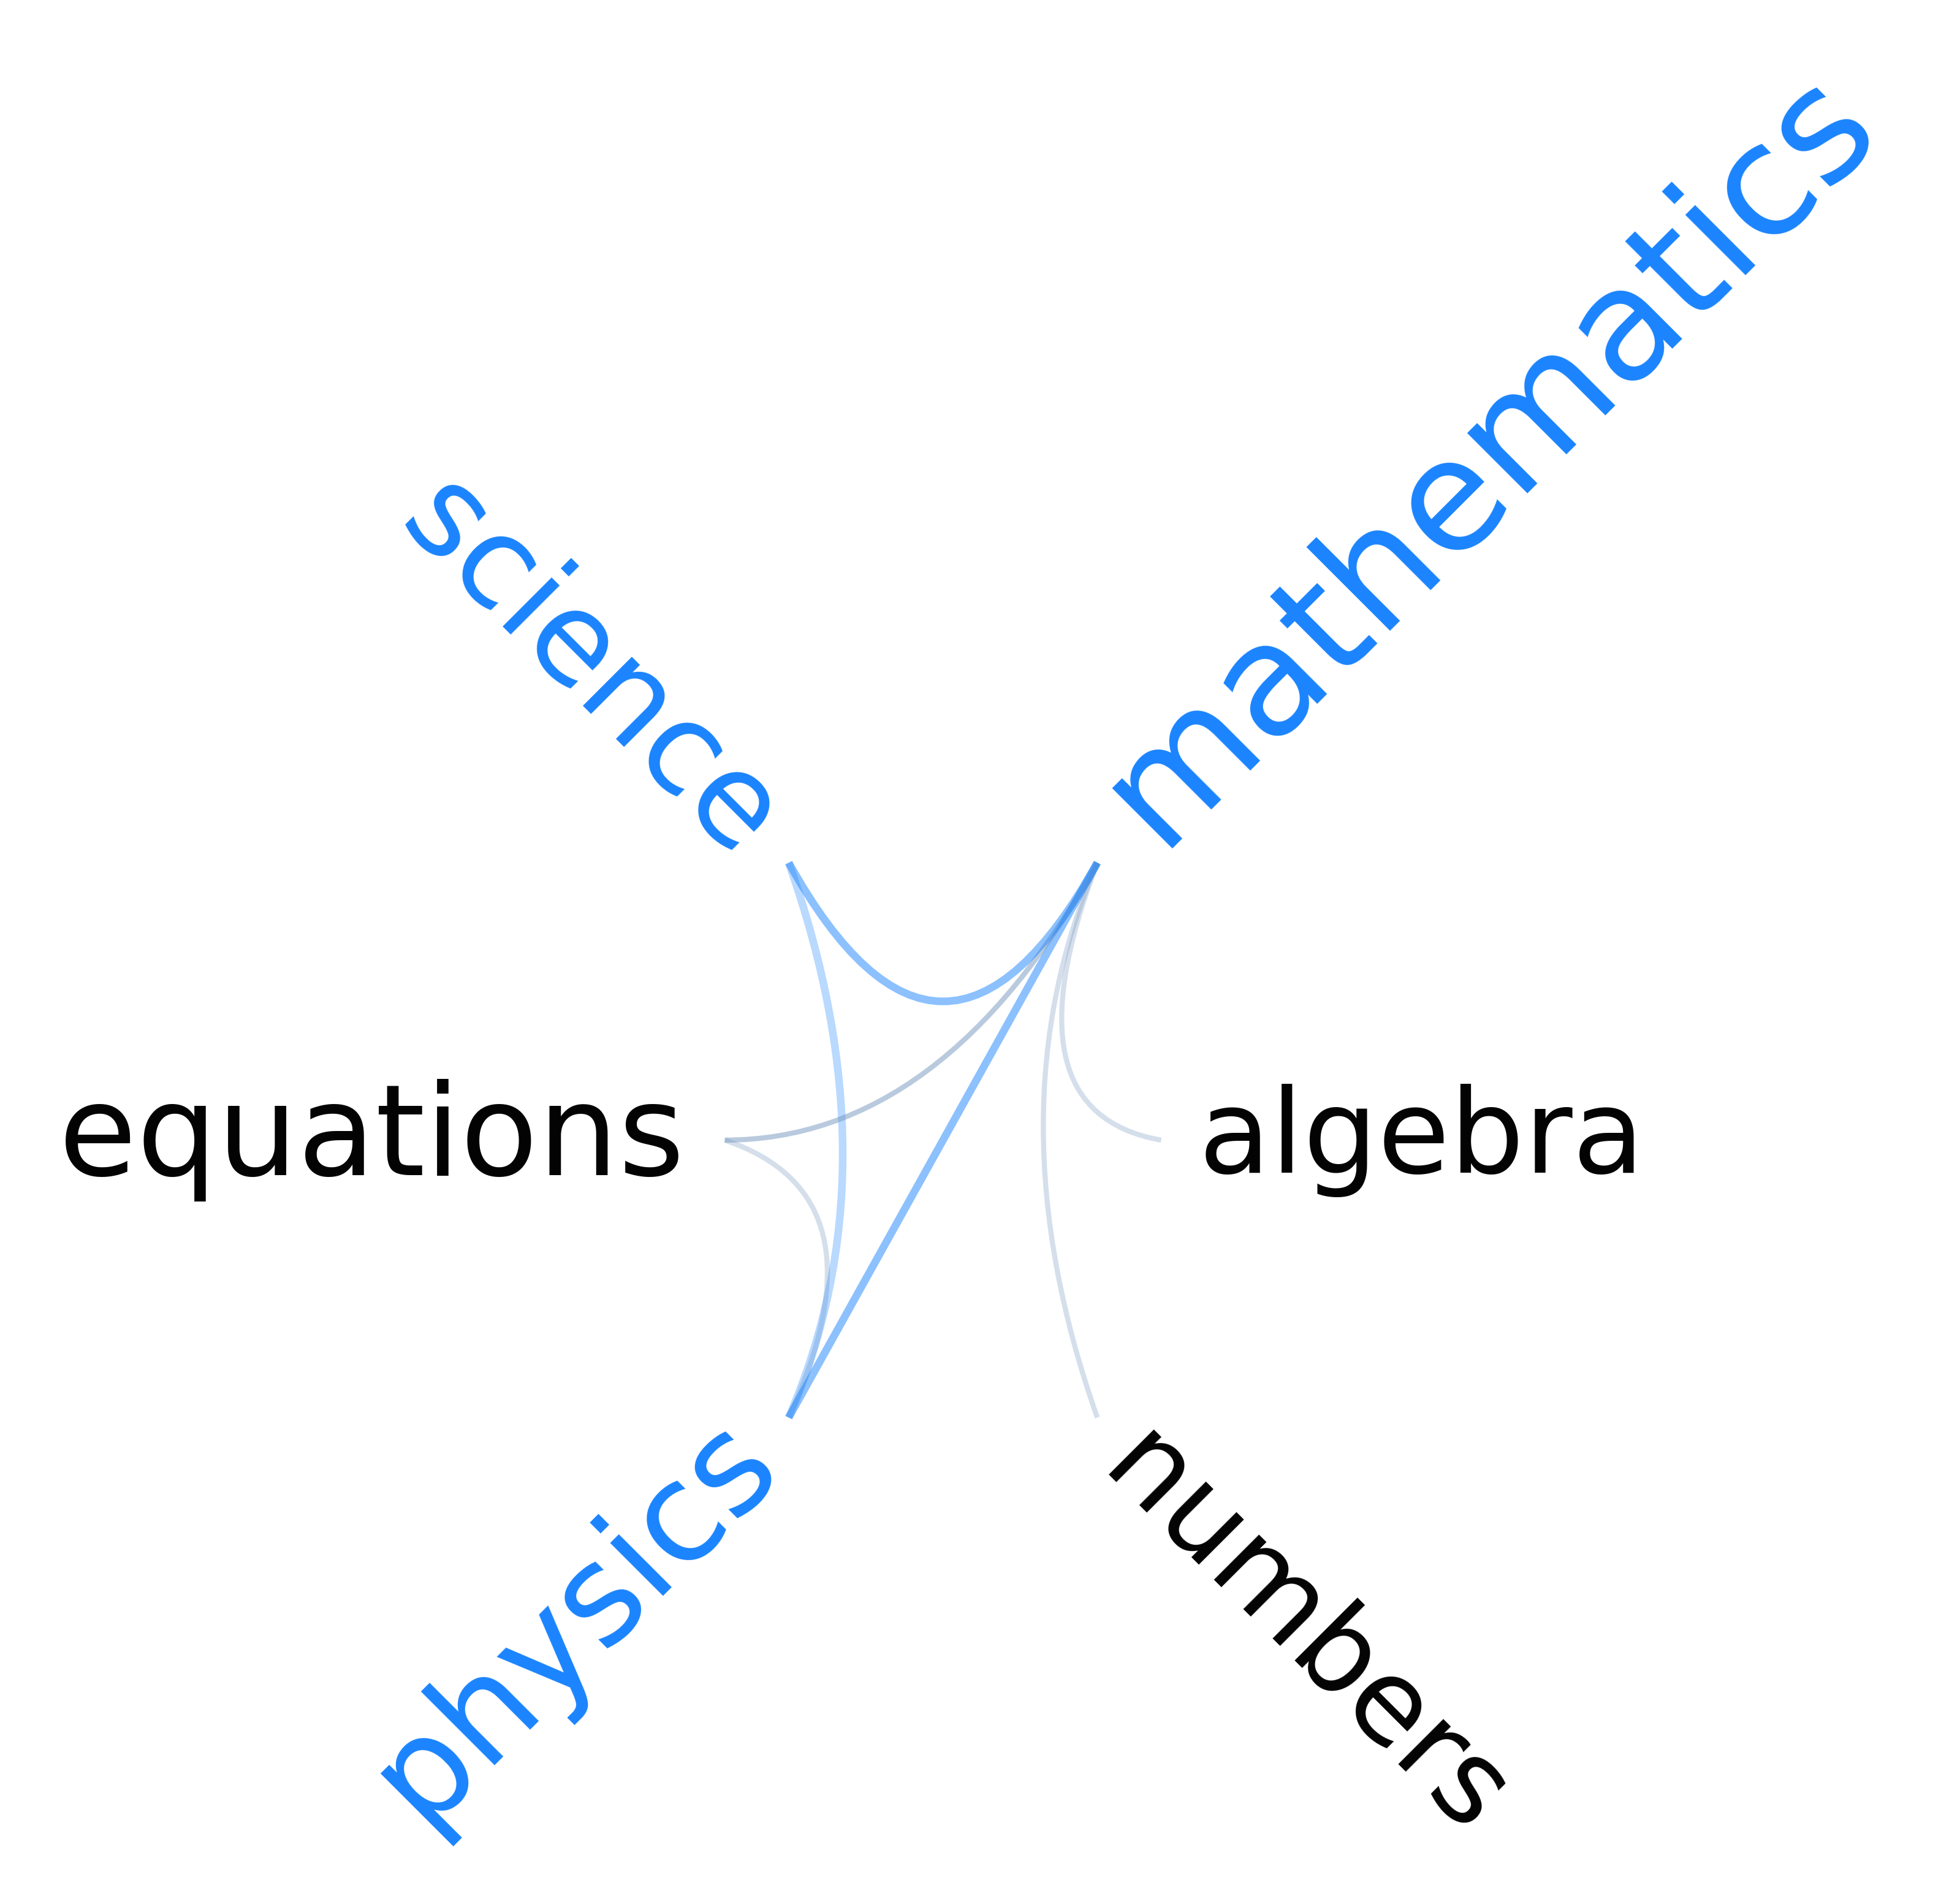

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:918: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:919: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_mathematics_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_mathematics_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3893.80 MB
Error processing flower for researchers_filtered_mathematics: name 'out_dir' is not defined
Error analyzing concreteness for 'mathematics': Empirical sample too small (<3). Got 1 scores.
Skipping 'anxiety': not in network or empty semantic frame.
Skipping 'stress': not in network or empty semantic frame.
Skipping 'depression': not in network or empty semantic frame.
Skipping 'statistics': not in network or empty semantic frame.
Skipping 'computer science': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3859.68 MB
Drawing TFM

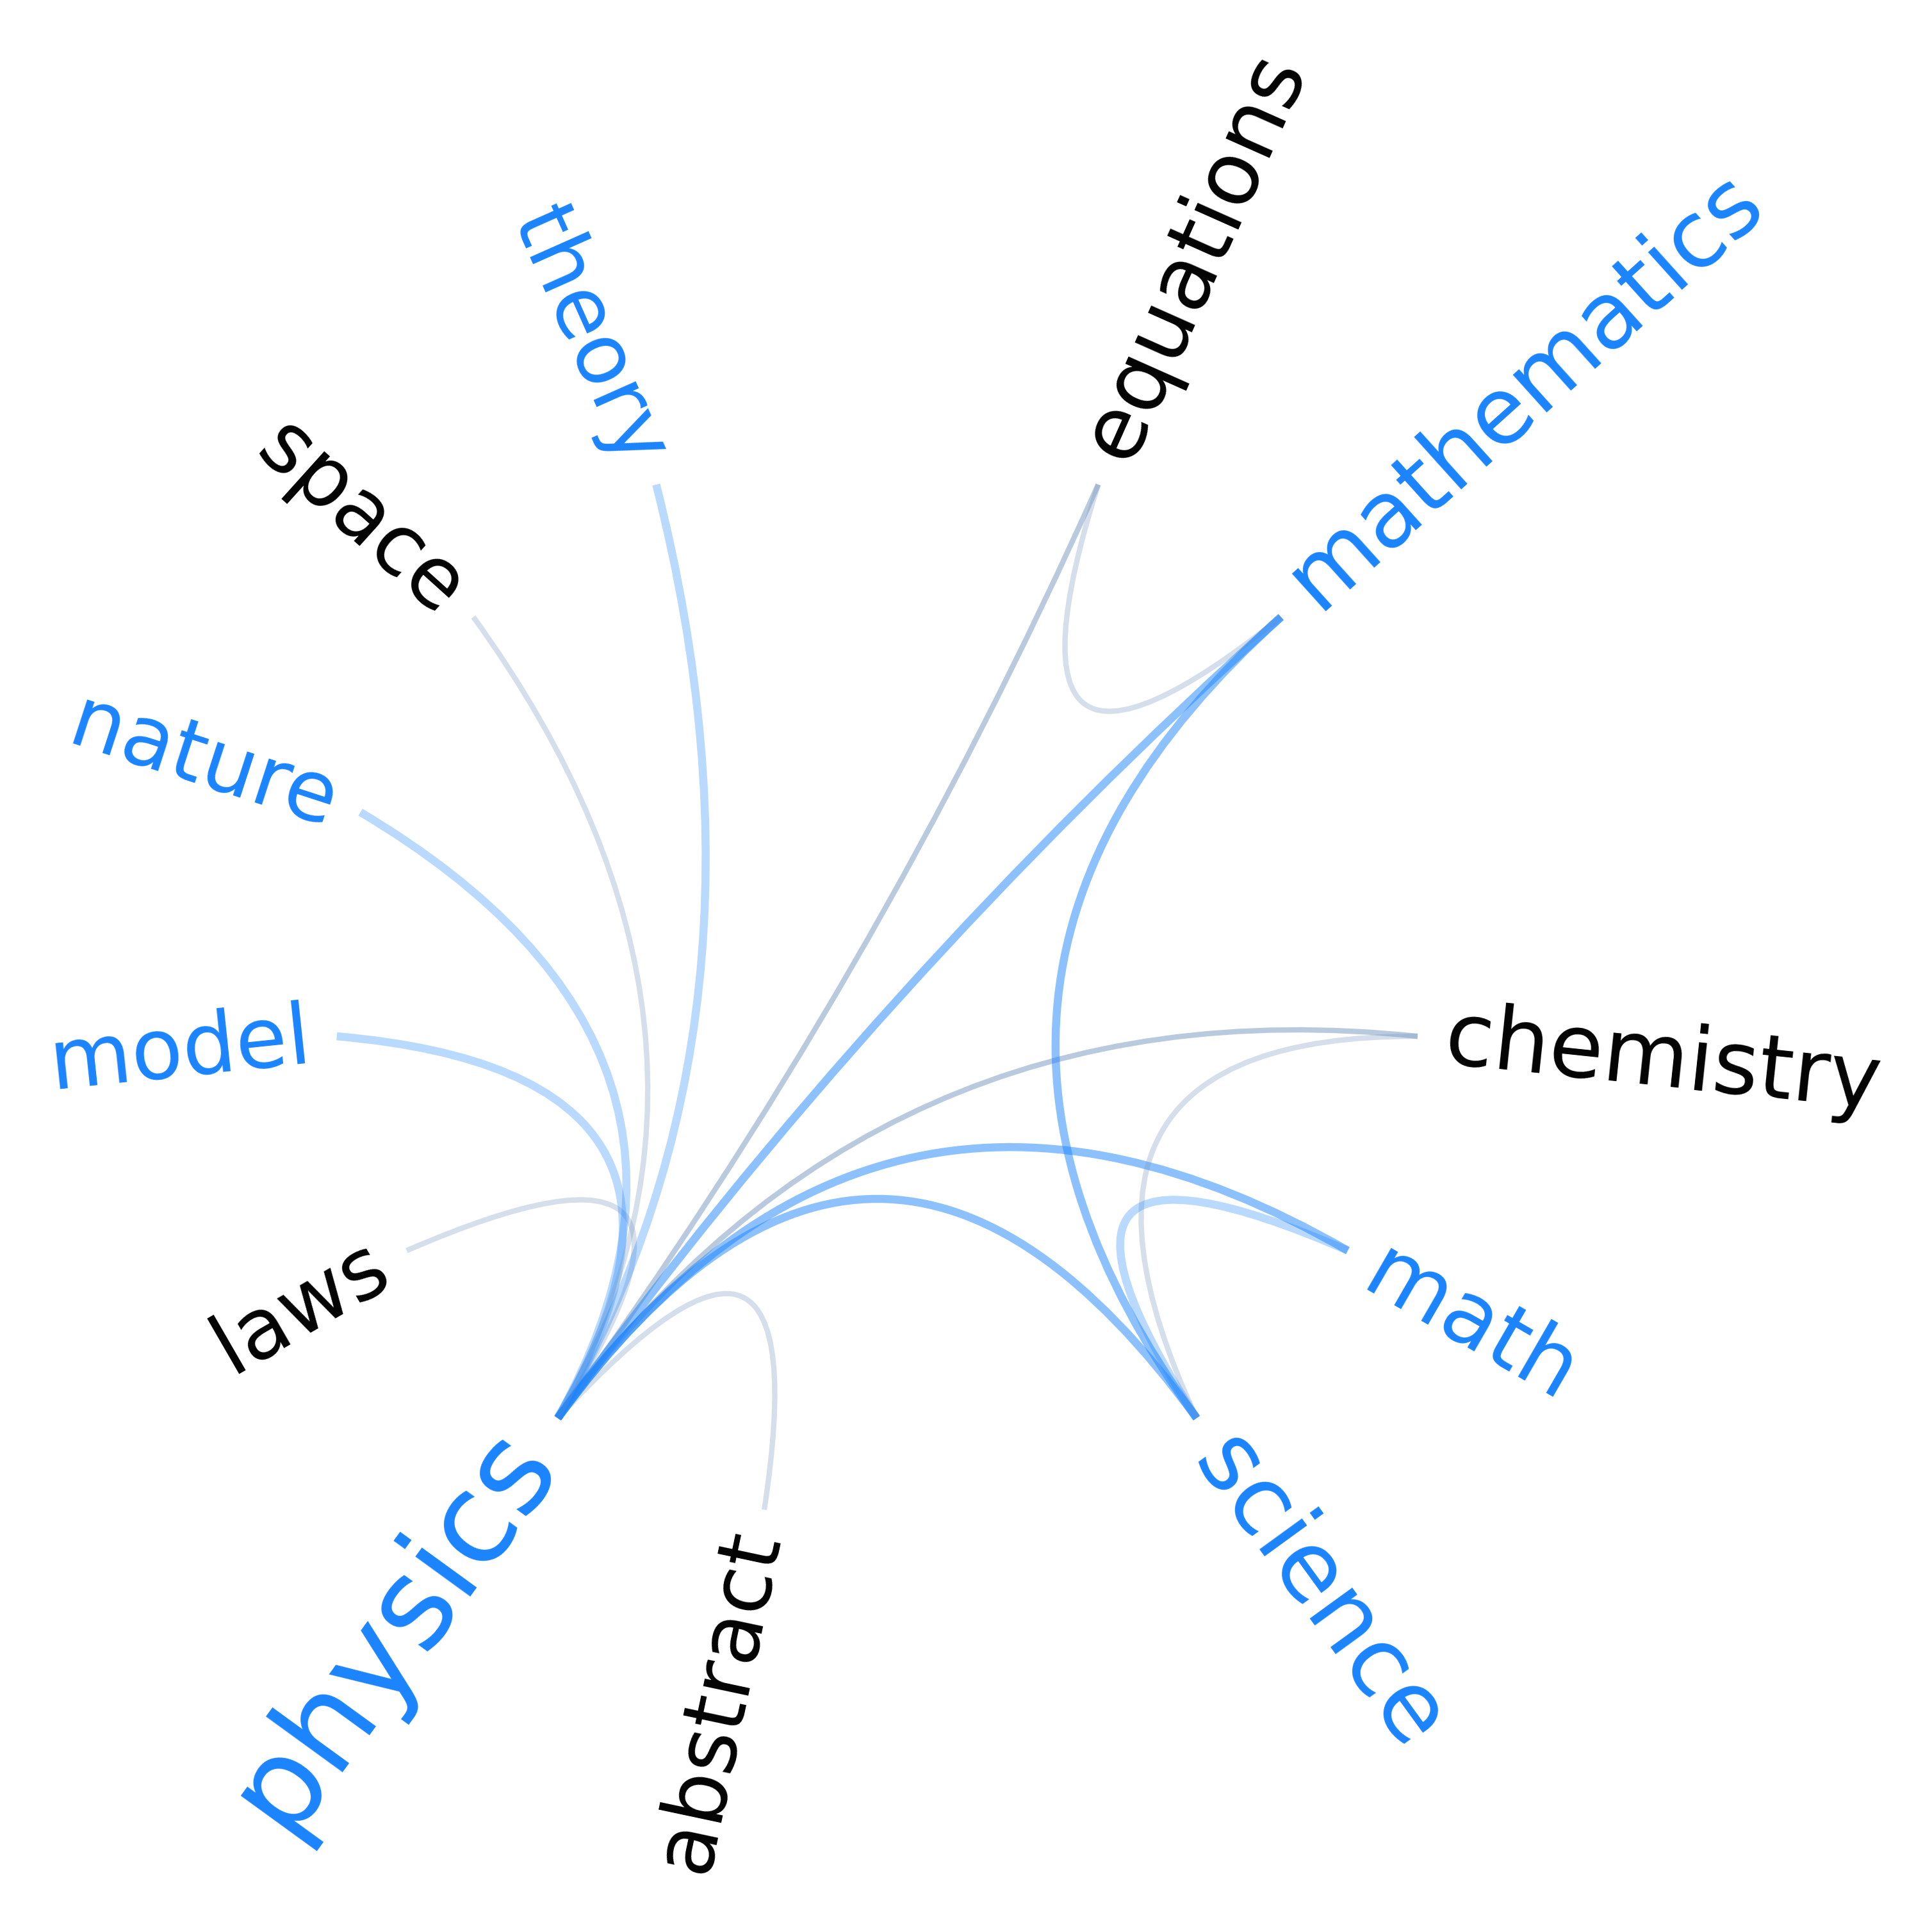

Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_physics_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_physics_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3894.47 MB
Error processing flower for researchers_filtered_physics: name 'out_dir' is not defined
Error analyzing concreteness for 'physics': Empirical sample too small (<3). Got 0 scores.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3859.91 MB
Drawing TFMN: researchers_filtered


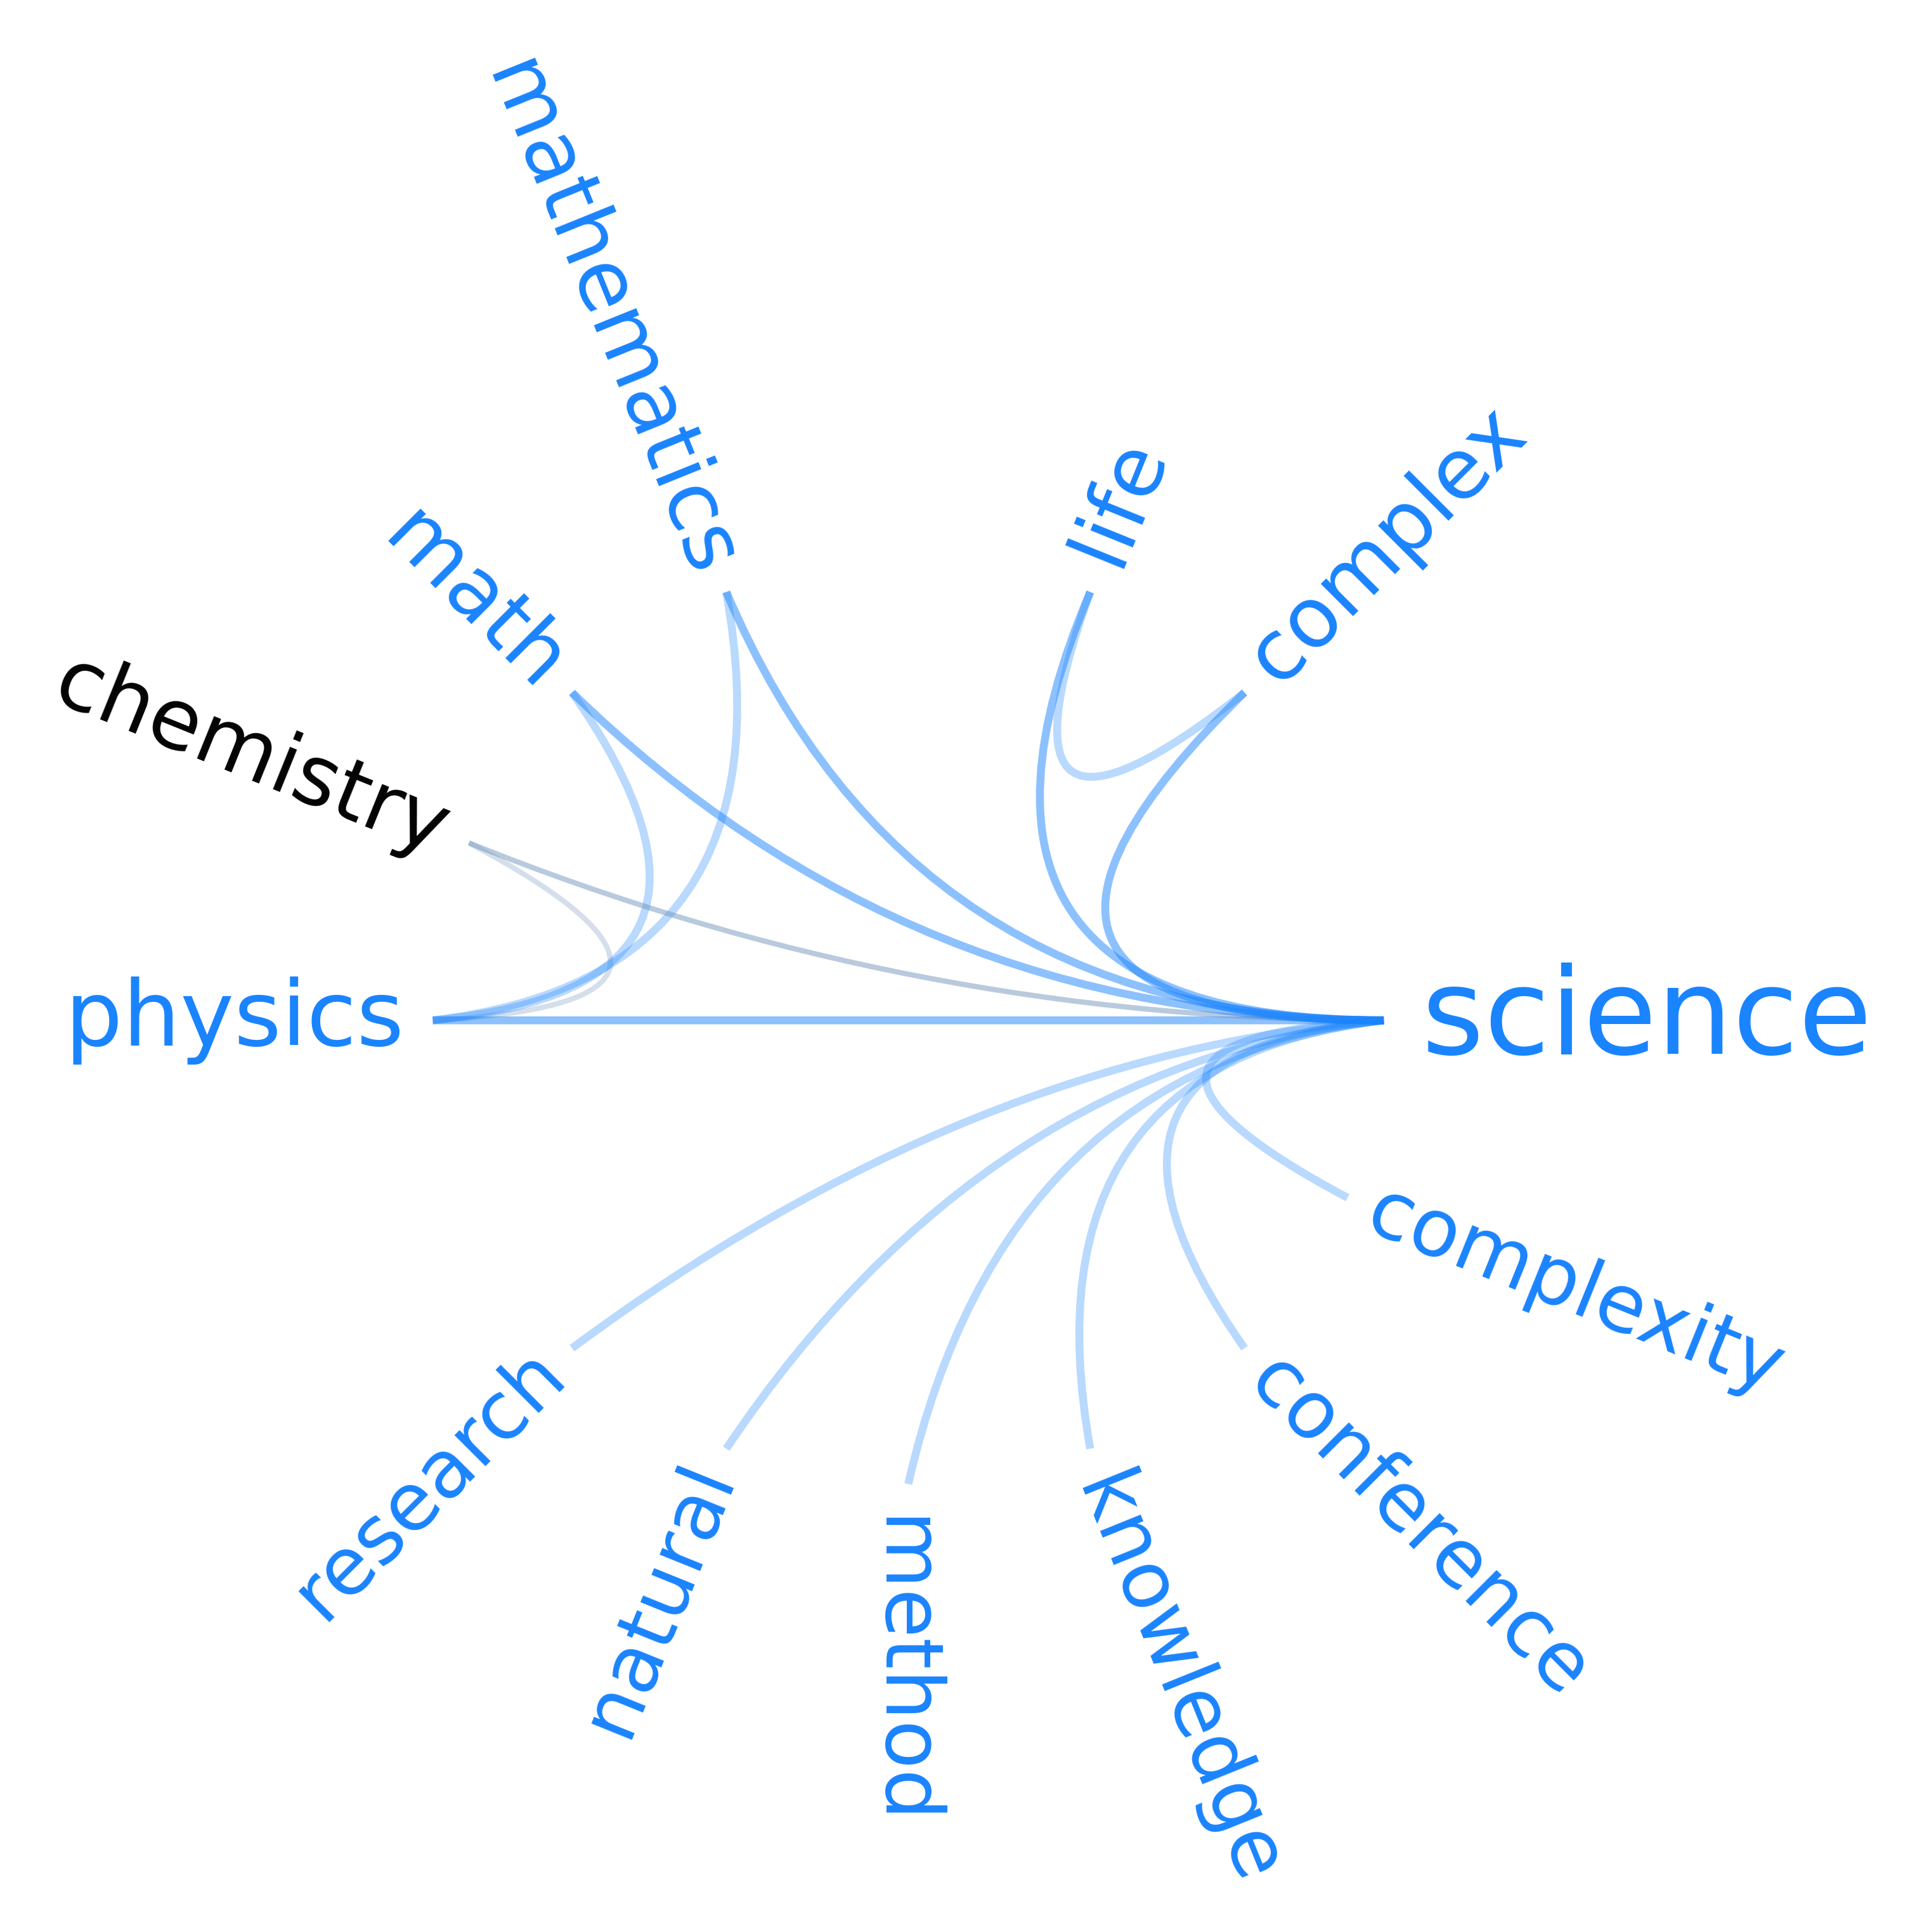

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3895.24 MB
Error processing flower for researchers_filtered_science: name 'out_dir' is not defined
Error analyzing concreteness for 'science': Empirical sample too small (<3). Got 0 scores.
Skipping 'exam': not in network or empty semantic frame.
Skipping 'grade': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3861.05 MB
Drawing TFMN: researchers_filtered


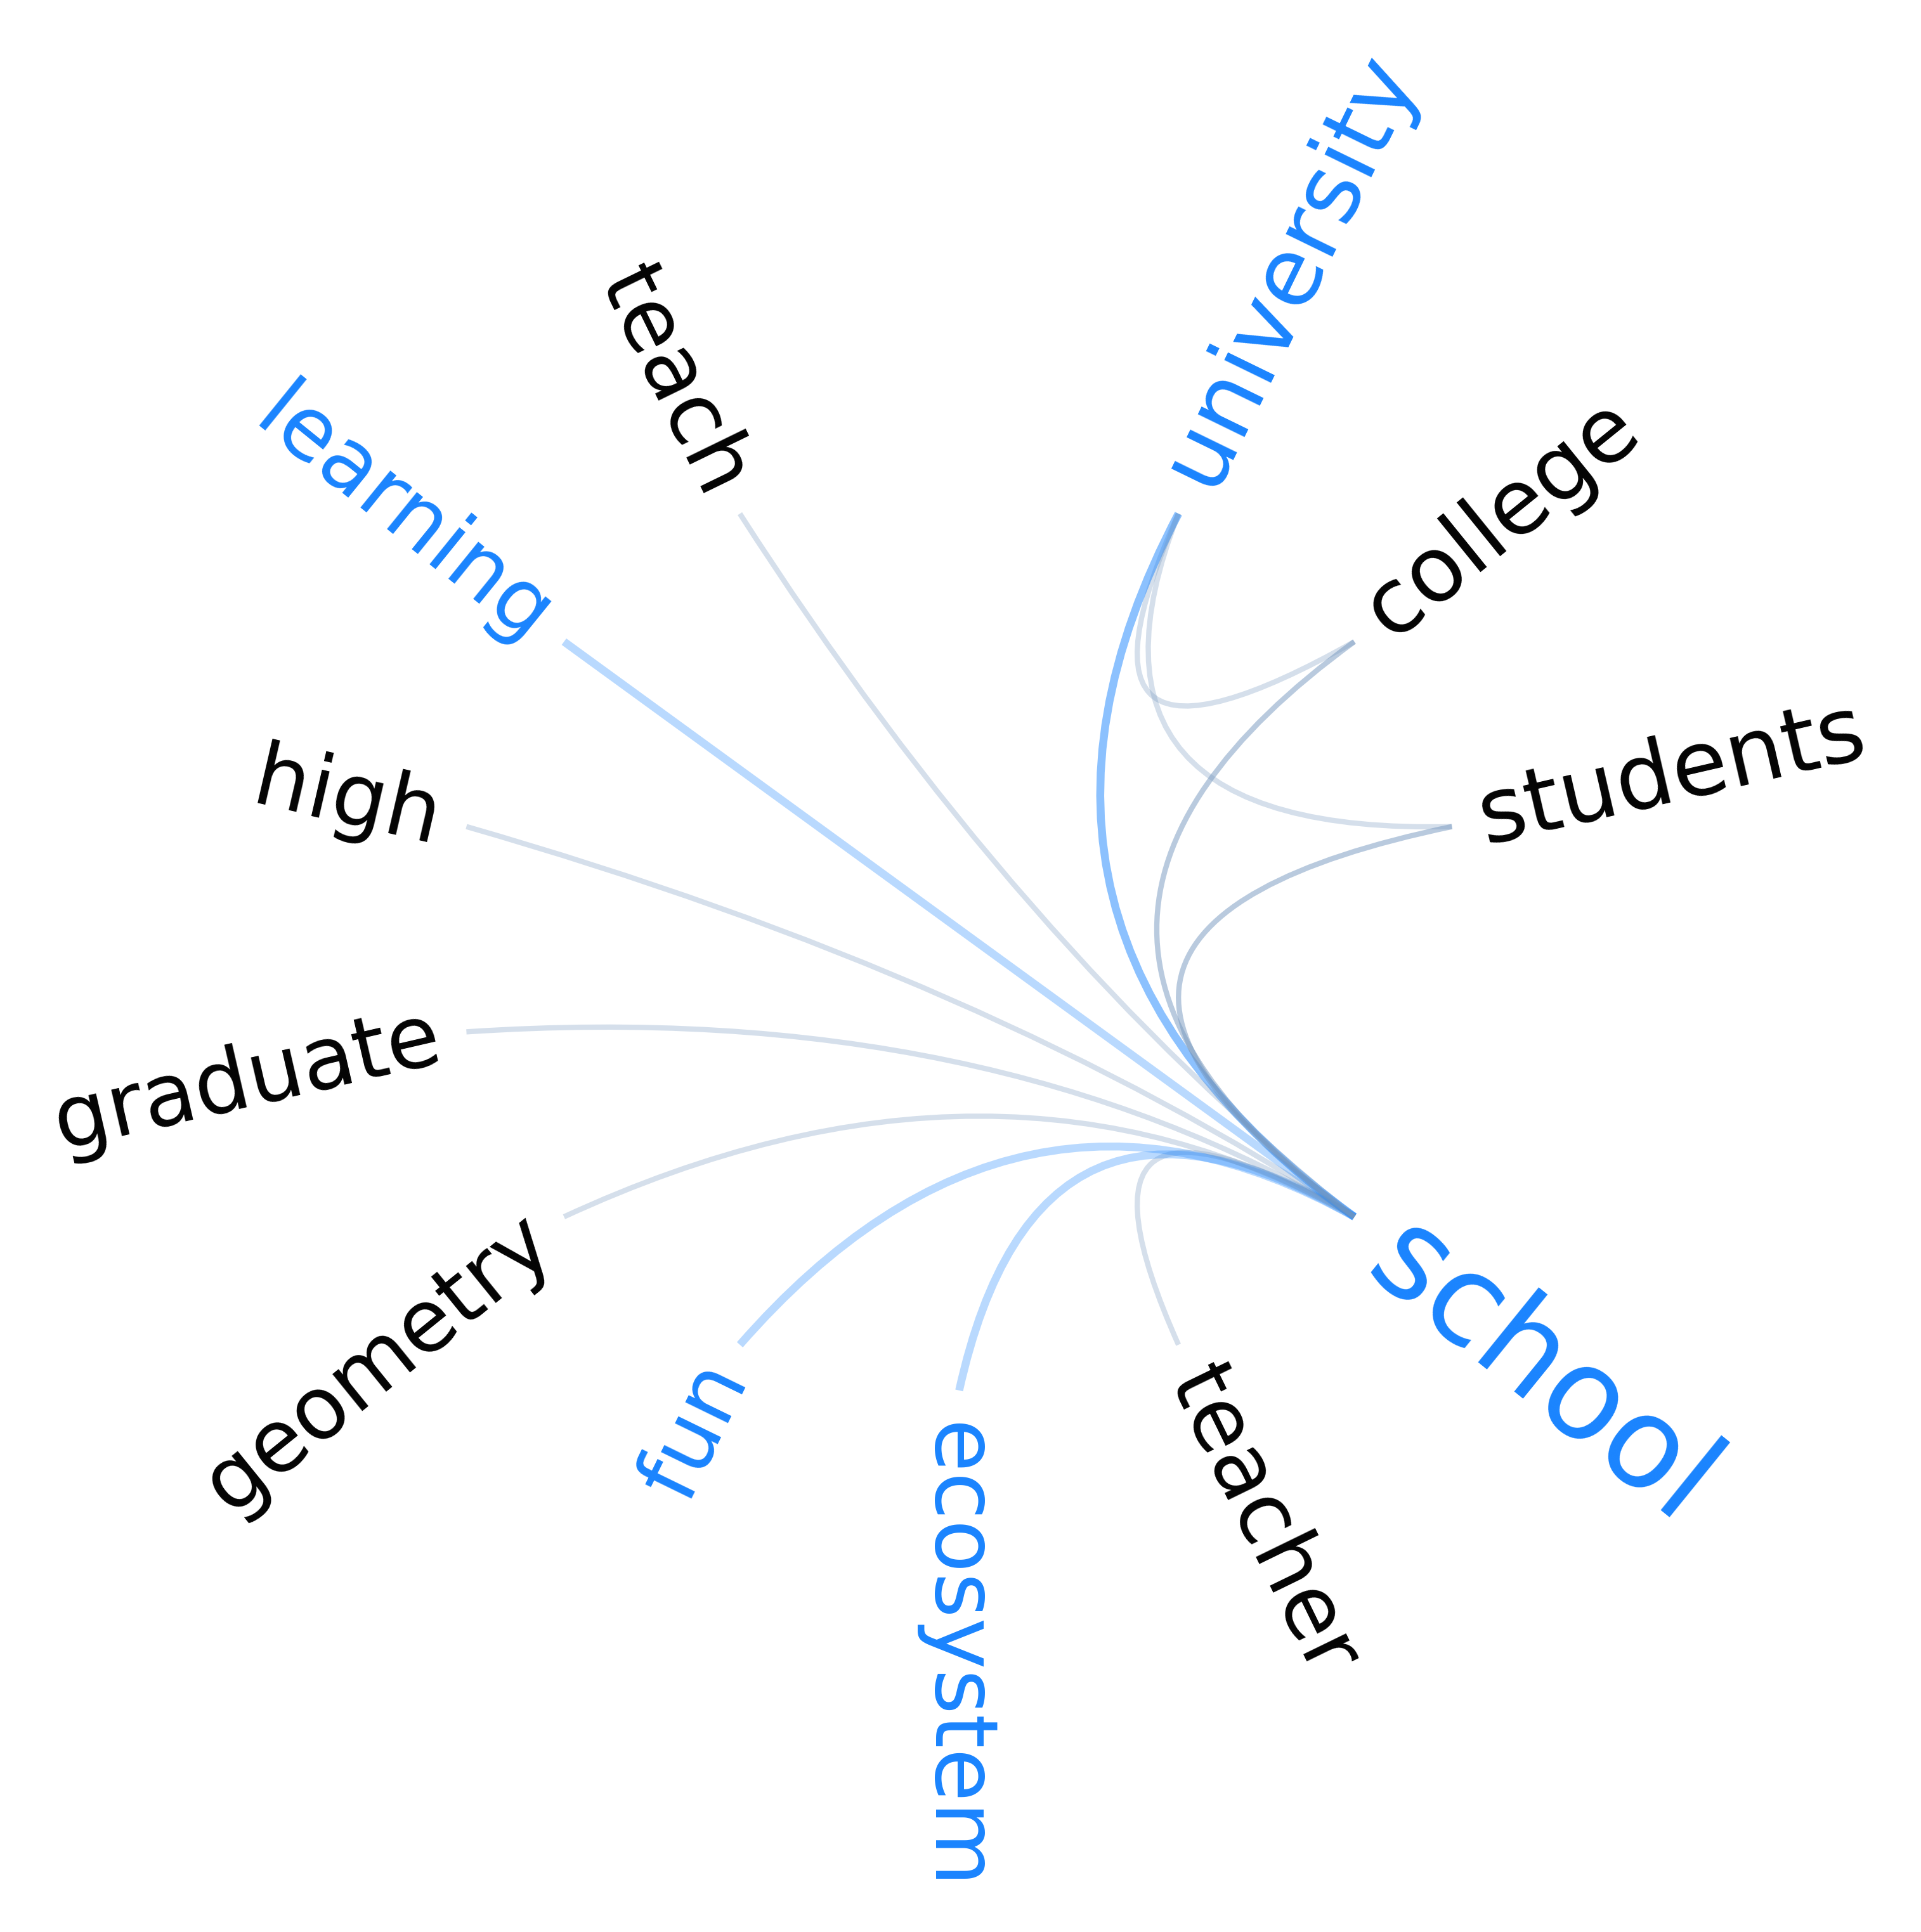

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_school_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_school_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3897.62 MB
Error processing flower for researchers_filtered_school: name 'out_dir' is not defined
Error analyzing concreteness for 'school': Empirical sample too small (<3). Got 1 scores.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3694.25 MB
Drawing TFMN: researchers_filtered


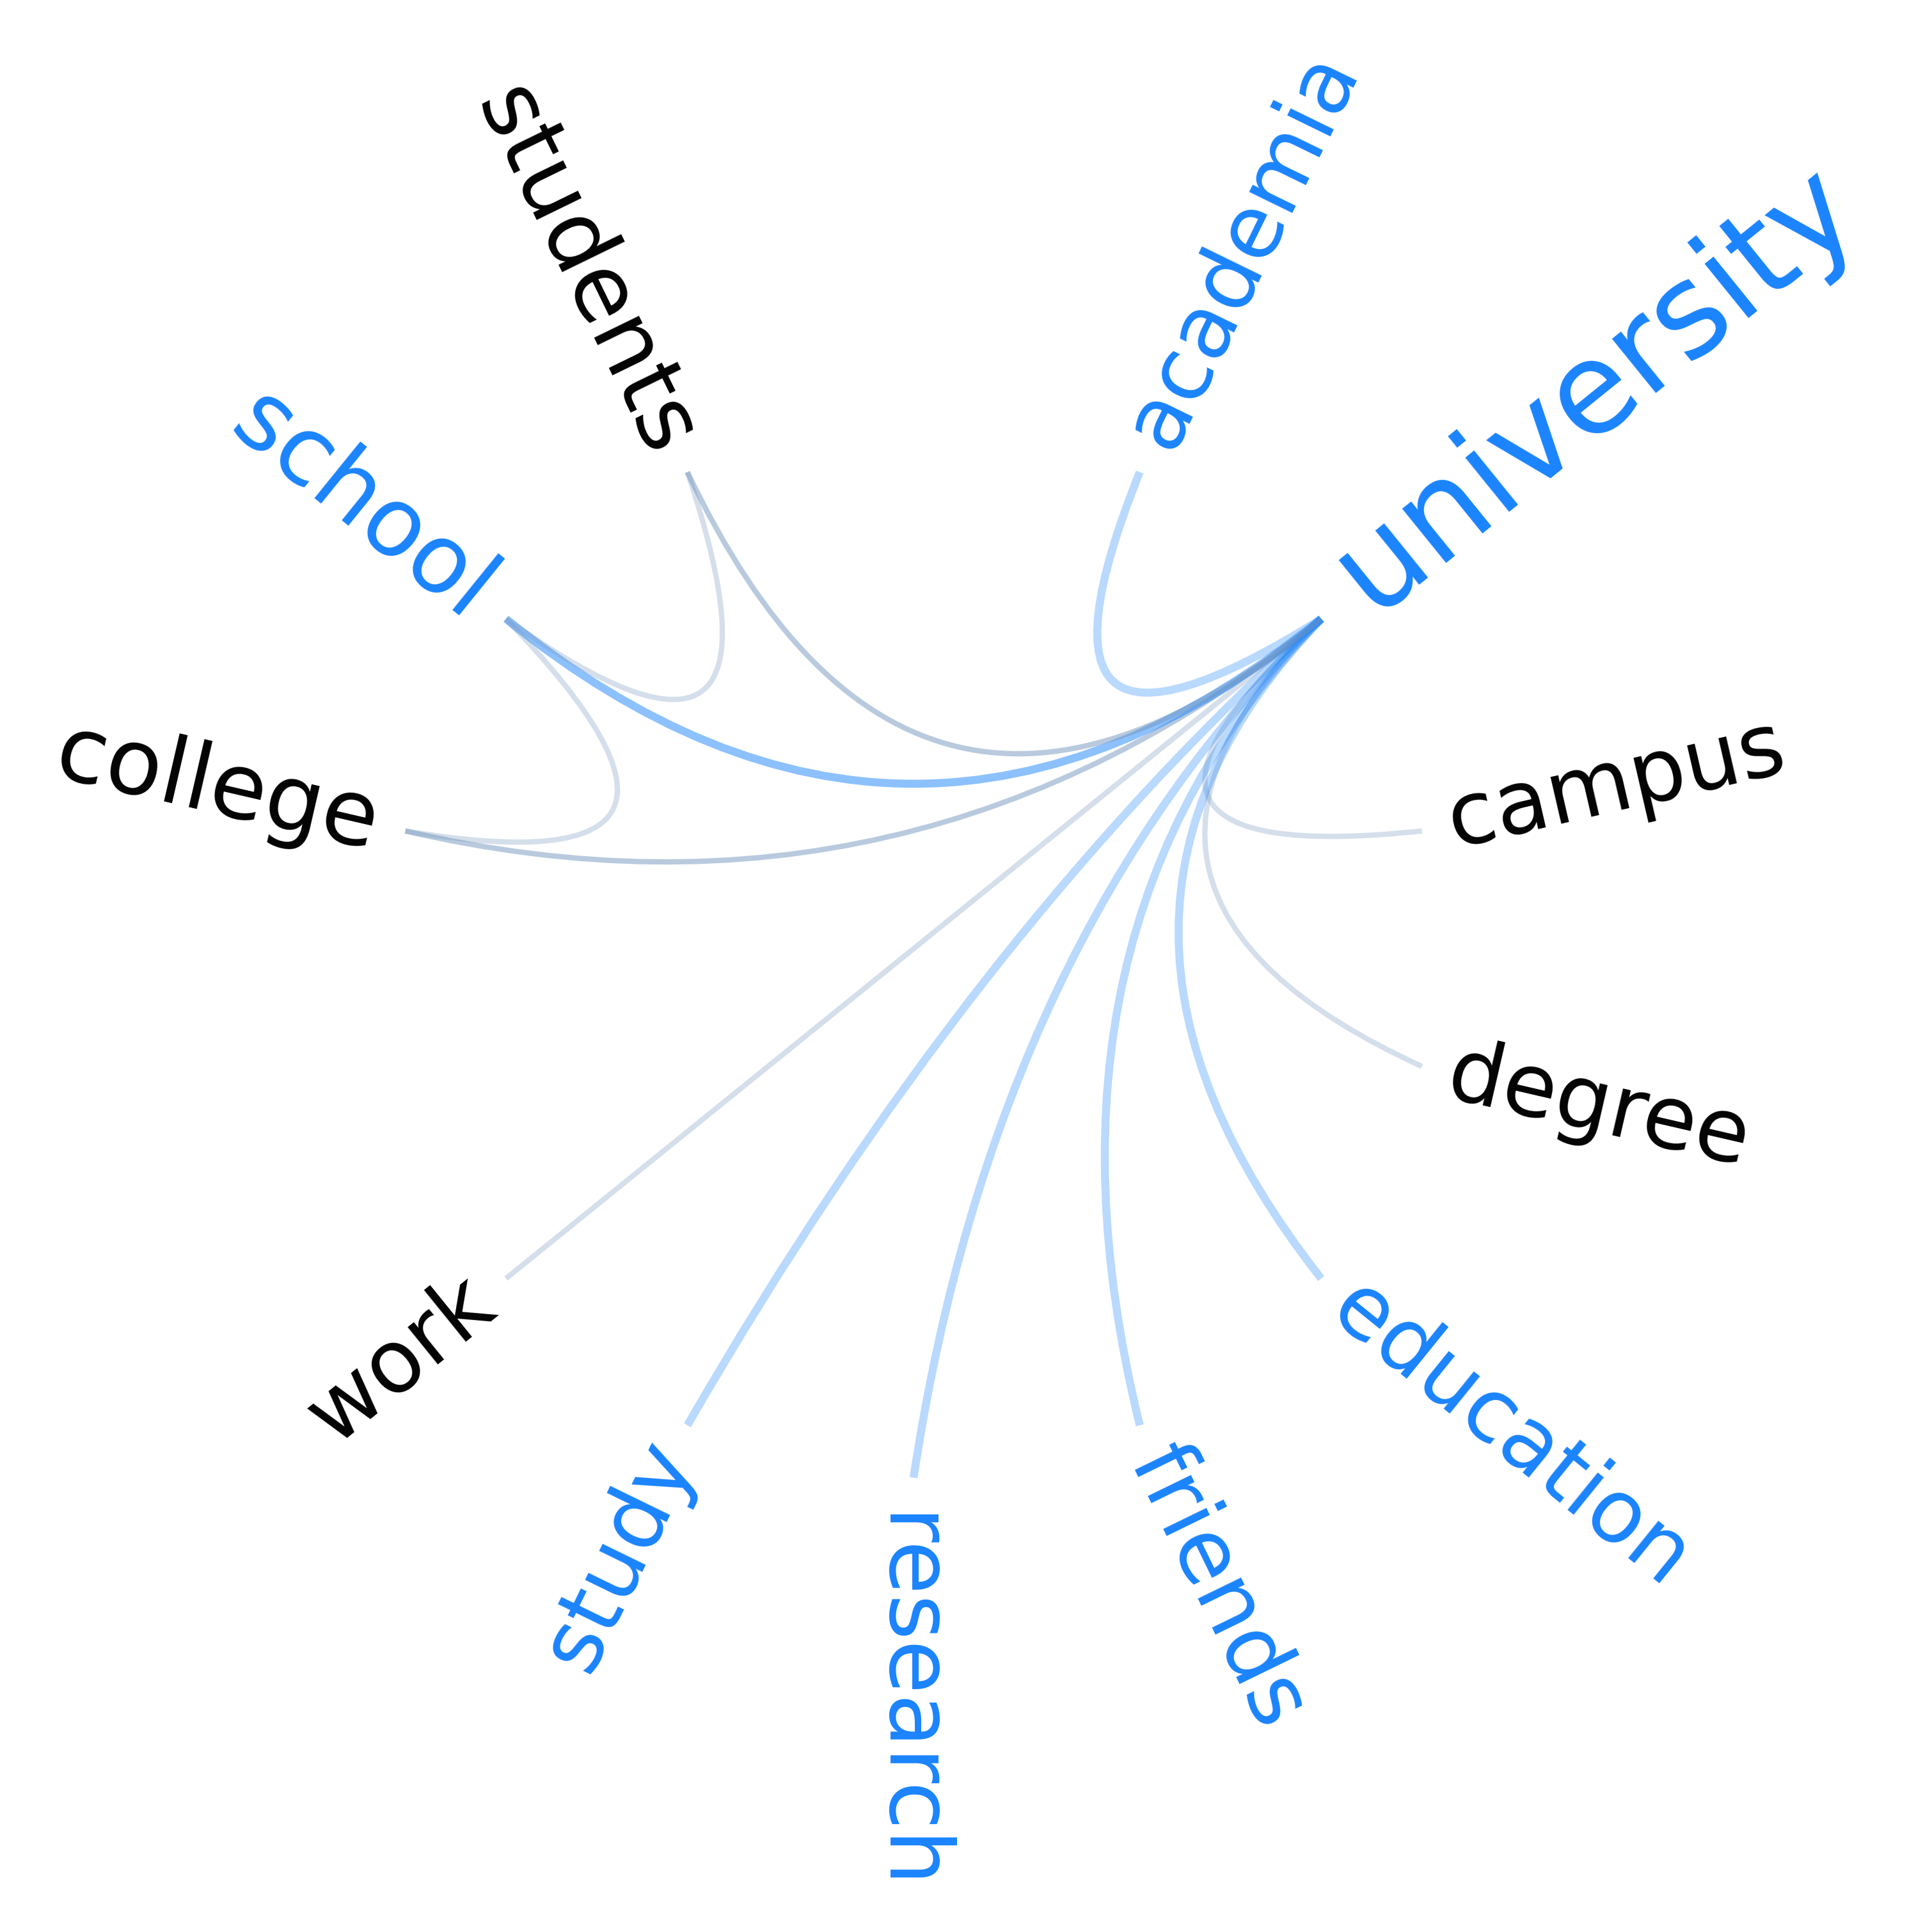

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_university_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_university_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3522.91 MB
Error processing flower for researchers_filtered_university: name 'out_dir' is not defined
Error analyzing concreteness for 'university': Empirical sample too small (<3). Got 2 scores.
Skipping 'calculus': not in network or empty semantic frame.
Skipping 'discipline': not in network or empty semantic frame.
Skipping 'subject': not in network or empty semantic frame.
Skipping 'scientist': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3328.26 MB
Drawing TFMN: researchers_filtered


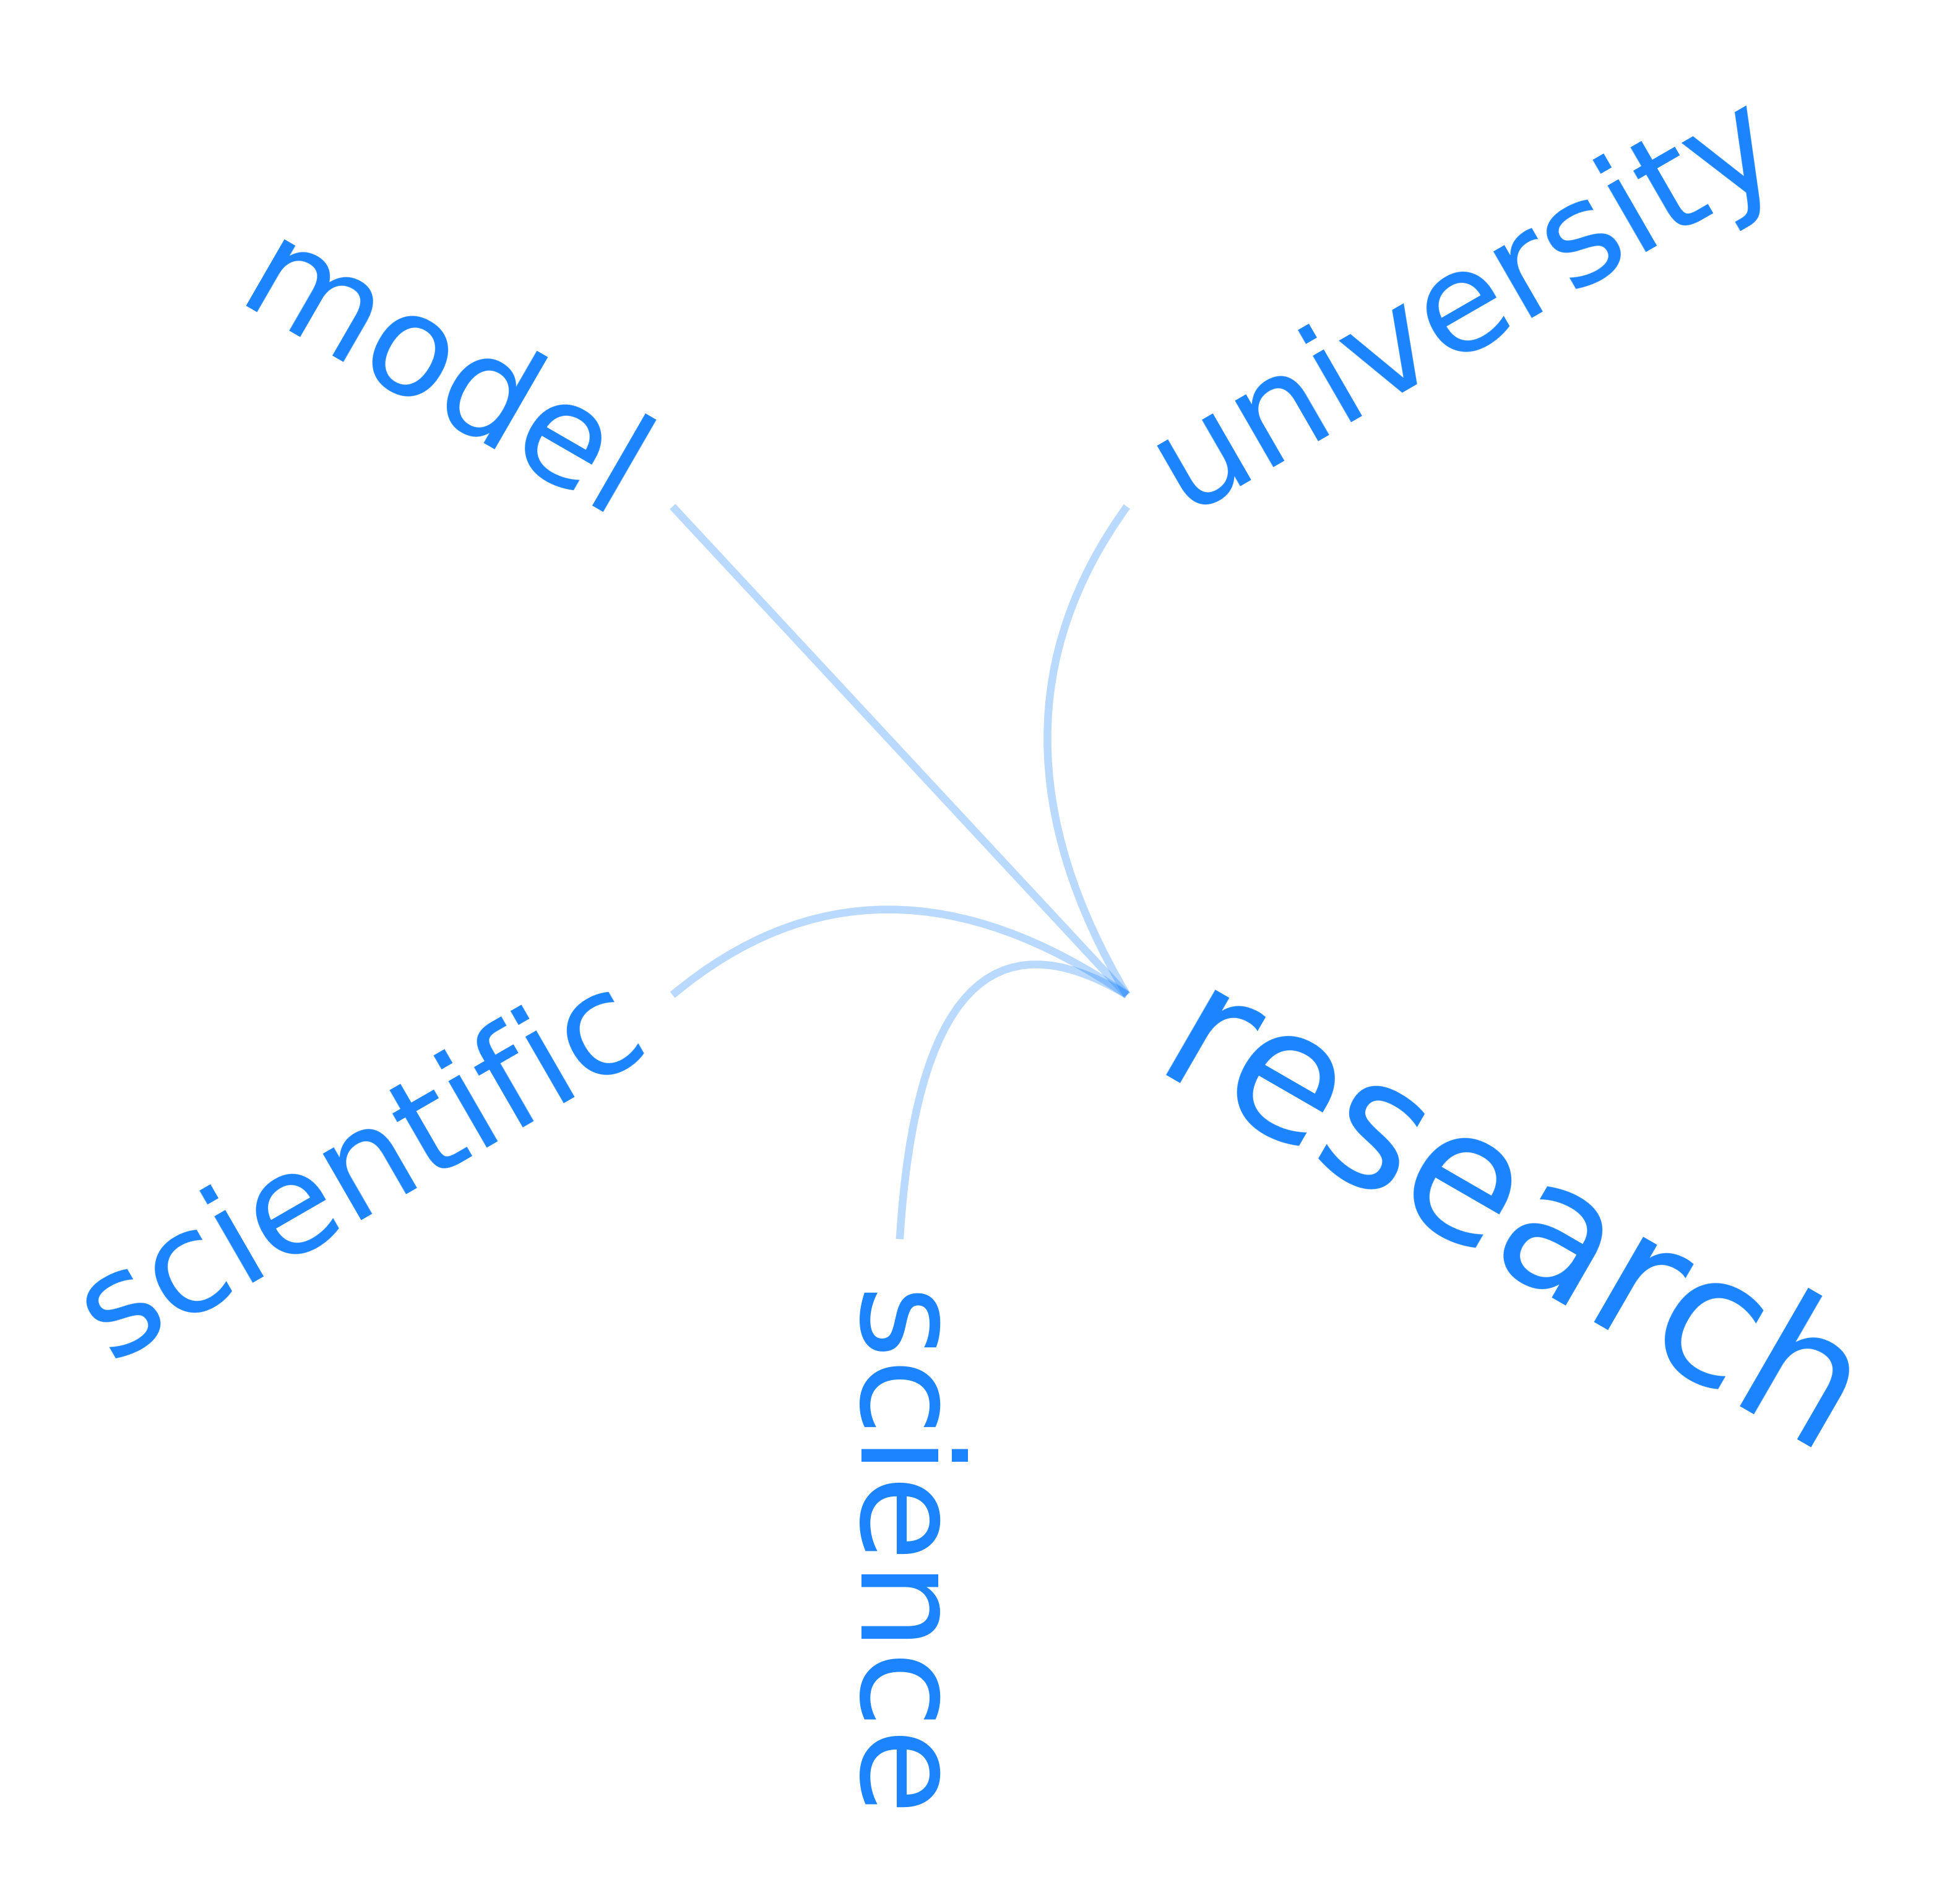

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:918: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:919: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_research_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_research_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3161.70 MB
Error processing flower for researchers_filtered_research: name 'out_dir' is not defined
Error analyzing concreteness for 'research': Empirical sample too small (<3). Got 0 scores.
Skipping 'well-being': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3119.12 MB
Drawing TFMN: researchers_filtered


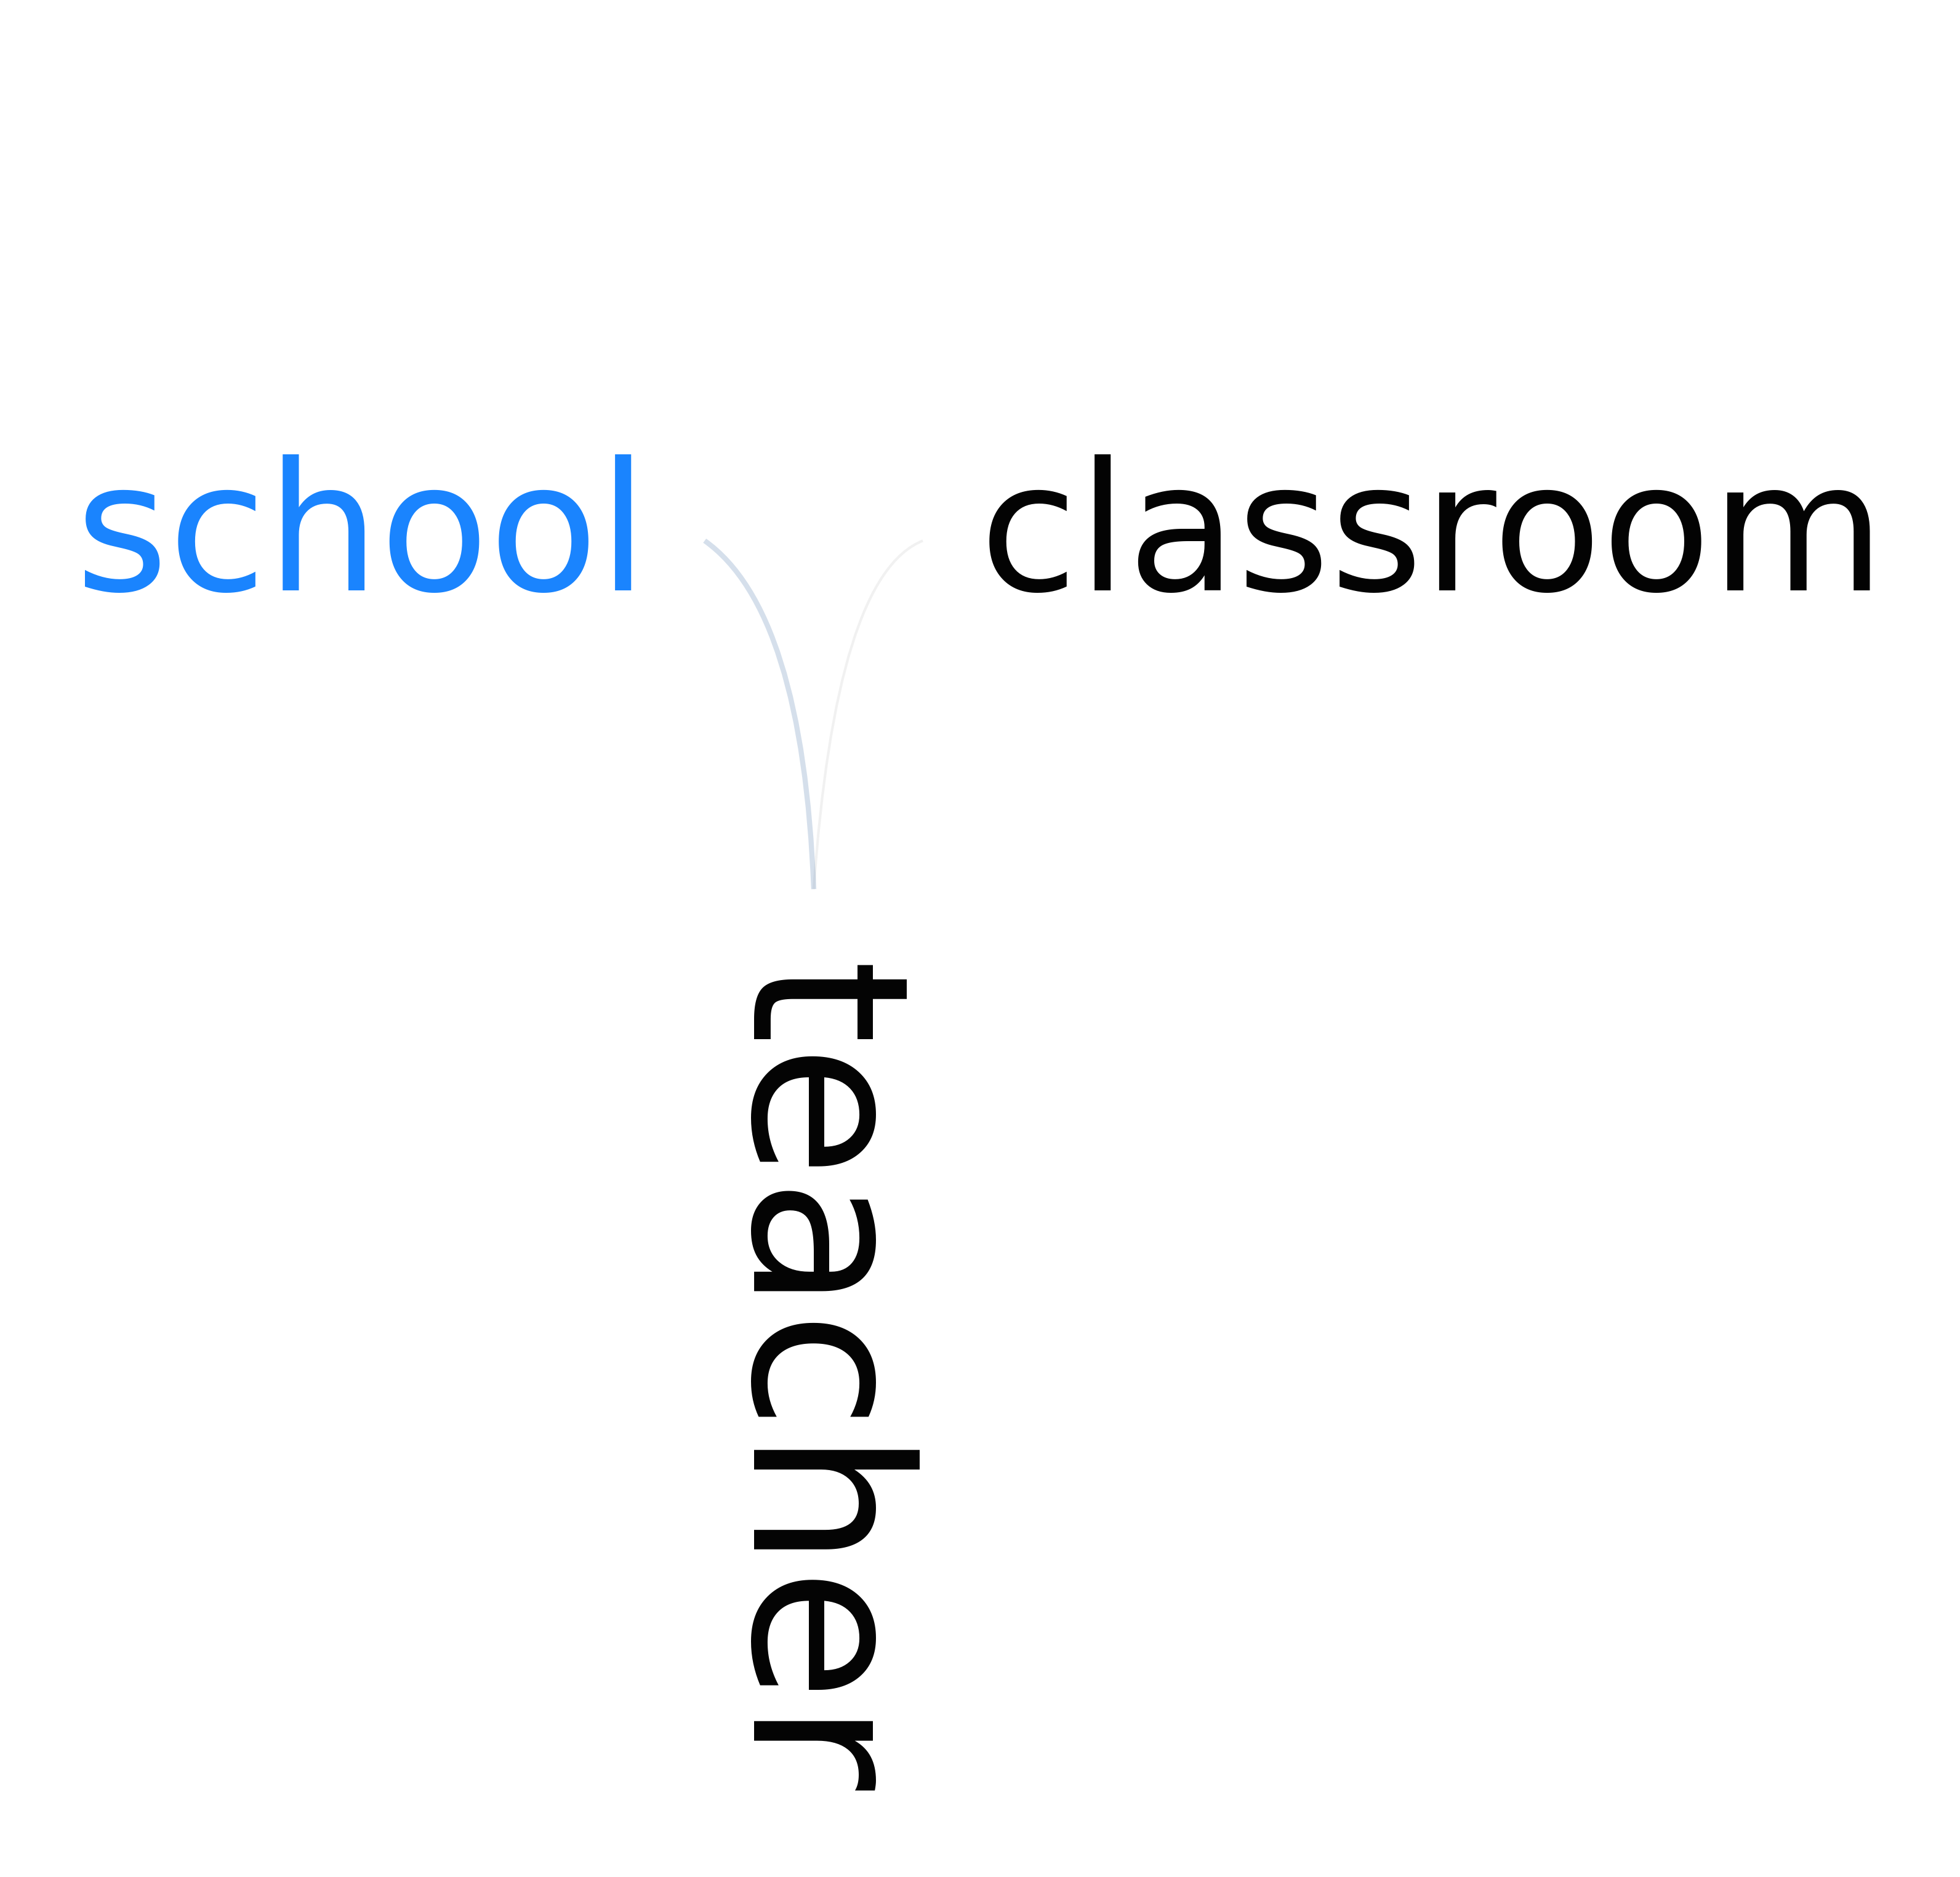

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:918: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
/home/franaz/coding/python/projects/data_science/networks/rassereno/fg_code/src/fmtools.py:919: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_teacher_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_teacher_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3135.82 MB
Error processing flower for researchers_filtered_teacher: name 'out_dir' is not defined
Error analyzing concreteness for 'teacher': Empirical sample too small (<3). Got 0 scores.
Skipping 'professor': not in network or empty semantic frame.
Current memory usage: 3090.12 MB
Valence stats: {'mean_valence': 0.18055555555555555, 'median_valence': 0.0, 'std_valence': 0.5851492898039138, 'n_positive_nodes': 40, 'n_negative_nodes': 14, 'n_neutral_nodes': 90, 'total_nodes': 144}
Graph with 144 nodes and 158 edges
Graph: [('abstract', {'valence_cat': 0}), ('physics', {'valence_cat': 1}), ('academia', {'valenc

/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/networkx/algorithms/assortativity/correlation.py:282: RuntimeWarning: invalid value encountered in scalar divide
  r = (t - s) / (1 - s)


Saved at ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.json
Saved at ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.txt
Current memory usage: 3093.38 MB
Saved structural features for 1 networks

Data saved to ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.csv

File researchers_filtered_structural_features.csv already exists in ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features. Use overwrite=True to replace it.
FMN: researchers_filtered
Before conversion to nx graph:
144 nodes and 158 edges

After conversion to nx graph:
Graph with 144 nodes and 158 edges

--------------------------------------------
Features for researchers_filtered:
--------------------------------------------
n_nodes 144
n_edges 158
n_positive_nodes 0
n_negative_nodes 0
mi

In [5]:
# Monitor initial memory usage
print("Starting pipeline...\n")

# Import the NetworkX graphs from txt files with custom valences
# Merge multiple edge Students files, filtered + unfiltered edges + student valences:
result = import_fmnt_from_old_text_format(
    files=[
        "../data/students_and_experts_stella_2019/Experts_Filtered.txt",
        "../data/students_and_experts_stella_2019/ValenceExperts.txt"
    ],
    alpha=0.1,
    min_occurrences=3,
    direction_stat="mean",
    directed=False
)

G_merged = result["graph"]
edges_df = result["edges"]
valence_df = result["valence_df"]
custom_valences = result["custom_valences"]

# Build the aggregated BFMN from the graph, keeping the custom valences
merged_fmn = emo.nxgraph_to_formamentis(G_merged)

monitor_memory()

# Export FMNs with custom valences
export_whole_fmn_multiple_custom(
    fmnts=[merged_fmn],
    save_path=files_output_dir,
    filename=f'{group_name}',
    custom_valences=custom_valences
)

# Load Brysbaert concreteness dataset
df_brysbaert = pd.read_csv('../data/brysbaert_concreteness_dataset_eng_ita/brysbaert_concreteness_dataset_eng_ita.csv')
# Draw and save semantic frame plots and emo flowers for each keyword
# for each keyword in keywords extract it, then draw the semantic
# frame plot, save it and show it in the notebook
layout = "edge_bundling"
if len(keywords) > 0:
    for keyword in keywords:
        semantic_frame = emo.extract_word_from_formamentis(merged_fmn, keyword)
        if not hasattr(semantic_frame, "vertices") or len(semantic_frame.vertices) == 0:
            print(f"Skipping '{keyword}': not in network or empty semantic frame.")
            continue
        out_dir = f'{base_output_path}/{files_output_dir}/visualizations'
        filename = f'{group_name}_{keyword}_{layout}_semantic_frame'
        draw_fmnts(
            fmnts={group_name: semantic_frame},
            out_dir=out_dir,
            layout=layout,
            highlight=[],
            thickness=1,
            ax=None,
            emo=emo,
            custom_valences=custom_valences,
            filename_base=filename,
        )
        make_emo_flowers(
            fmnts={f'{group_name}_{keyword}': semantic_frame},
            save_path=out_dir,
            filename=f'{group_name}_{keyword}_emo_flower',
            emo=emo,
            batch_size=1
        )

        if use_prelemmatized_brysbaert:
                # Analyze concreteness of the semantic frame (fast, pre-lemmatized datasets)
                try:
                    result = emo.analyze_semantic_frame_concreteness_fast(
                        semantic_frame,
                        seed=None,
                        save_json_path=f'{base_output_path}/{files_output_dir}/analysis/{group_name}_{keyword}_concreteness_analysis.json',
                        save_figure_path=f'{base_output_path}/{files_output_dir}/visualizations/{group_name}_{keyword}_concreteness_analysis.png',
                        plot=True
                    )
                    print(result['p_value'])
                    print(f"Concreteness analysis for '{keyword}' saved successfully.")
                except Exception as e:
                    print(f"Error analyzing concreteness for '{keyword}': {e}")
            
        else:
            # Analyze concreteness of the semantic frame
            try:
                result = emo.analyze_semantic_frame_concreteness(
                    semantic_frame,
                    df_brysbaert,
                    seed=None,
                    save_json_path=f'{base_output_path}/{files_output_dir}/analysis/{group_name}_{keyword}_concreteness_analysis.json',
                    save_figure_path=f'{base_output_path}/{files_output_dir}/visualizations/{group_name}_{keyword}_concreteness_analysis.png',
                    plot=True
                )
                print(result['p_value'])
                print(f"Concreteness analysis for '{keyword}' saved successfully.")
            except Exception as e:
                print(f"Error analyzing concreteness for '{keyword}': {e}")

monitor_memory()

valence_stats = fmn_valence_stats(merged_fmn, custom_valences, emo=emo)
print("Valence stats:", valence_stats)

print(G_merged)
print("Graph:", G_merged.nodes(data=True))
print("Custom valences:", custom_valences)

# Make a dictionary of the merged BFMN for further processing
if merged_fmn is not None:
    bfmns = {fmn_type: merged_fmn}

# Compute node_valence_maps for the merged BFMN
# Collect node valences separately (cannot attach to namedtuple)
node_val_maps = {}
node_val_maps[fmn_type] = {n: d.get("valence_cat") for n, d in G_merged.nodes(data=True)}

'''valence_stats = fmn_valence_stats(merged_fmn, custom_valences, emo=emo)
print("Valence stats:", valence_stats)

# Inspect the merged BFMN
inspect_fmn(
    fmn=merged_fmn,
    participant=group_name,
    all_features={group_name: valence_stats},
    emo=emo
)'''

# Check for presence of each keyword in the fmn
verify_and_report_nodes(
    fmns={group_name: merged_fmn},
    required=keywords
)

# Compute and export structural features for the aggregated FMN
aggregated_features = extract_bfmn_structural_features(
    fmnts={group_name: merged_fmn},
    save_path=f'{base_output_path}/{files_output_dir}/structural_features',
    emo=emo,
    batch_size=1,
    node_valence_maps=node_val_maps,
    persist=True
)

# Convert features to DataFrame and export
aggregated_features_df = all_fmns_features_df(aggregated_features, orient="participants")
export_df(aggregated_features_df, f'{base_output_path}/{files_output_dir}/structural_features', filename=f'{group_name}_structural_features')

aggregated_features_df = all_fmns_features_df(aggregated_features, orient="participants")
export_df(aggregated_features_df, f'{base_output_path}/{files_output_dir}/structural_features', filename=f'{group_name}_structural_features')

# Inspect the created fmnts
inspect_fmn(
    fmn=merged_fmn,
    participant=group_name,
    all_features=aggregated_features,
    emo=emo
)

### Verifying keywords presence in the networks

In [6]:
# Verify presence of nodes "ansia", "matematica", "stress" and "depressione" in all BFMNs
check_summary = verify_and_report_nodes(
    fmns={fmn_type: merged_fmn},
    required=keywords,
)

print(check_summary)

Presence of nodes ['mathematics', 'anxiety', 'stress', 'depression', 'statistics', 'computer science', 'physics', 'science', 'exam', 'grade', 'school', 'university', 'calculus', 'discipline', 'subject', 'scientist', 'research', 'well-being', 'teacher', 'professor'] in all FMNs:
FMN 'researchers_filtered_bfmns' missing: ['anxiety', 'stress', 'depression', 'statistics', 'computer science', 'exam', 'grade', 'calculus', 'discipline', 'subject', 'scientist', 'well-being', 'professor']

Networks satisfying (ALL of ['mathematics', 'anxiety', 'stress', 'depression', 'statistics', 'computer science', 'physics', 'science', 'exam', 'grade', 'school', 'university', 'calculus', 'discipline', 'subject', 'scientist', 'research', 'well-being', 'teacher', 'professor']): 0/1 (0.00%)
Presence 'mathematics': 1/1 (100.00%)

Presence 'anxiety': 0/1 (0.00%)

Presence 'stress': 0/1 (0.00%)

Presence 'depression': 0/1 (0.00%)

Presence 'statistics': 0/1 (0.00%)

Presence 'computer science': 0/1 (0.00%)

Presen

In [7]:
# Print number of nodes and edges (are the same as the ones imported: good!)
print(f"\nBFMN 2024 has {len(merged_fmn.vertices)} nodes and {len(merged_fmn.edges)} edges.")
print(f"BFMN 2025 has {len(merged_fmn.vertices)} nodes and {len(merged_fmn.edges)} edges.")

valence_stats_2025 = fmn_valence_stats(merged_fmn, custom_valences, emo=emo)
print("Valence stats 2025:", valence_stats_2025)


BFMN 2024 has 144 nodes and 158 edges.
BFMN 2025 has 144 nodes and 158 edges.
Valence stats 2025: {'mean_valence': 0.18055555555555555, 'median_valence': 0.0, 'std_valence': 0.5851492898039138, 'n_positive_nodes': 40, 'n_negative_nodes': 14, 'n_neutral_nodes': 90, 'total_nodes': 144}
